In [1]:
!pip install transformers datasets accelerate scikit-learn

Import the libraries

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", __import__("sklearn").__version__)



NumPy version: 2.1.3
Pandas version: 2.2.3
Scikit-learn version: 1.6.1


Load the three CSV files

# Toxicity Classification Using XLM-RoBERTa

## Project Overview

This project performs 3-class toxicity classification using a fine-tuned XLM-RoBERTa model.

The model classifies text into the following three categories:

- Explicitly Toxic
- Subtly Toxic
- Non-toxic

The provided training dataset is used for model training and validation, and the trained model is then used to predict labels for the test dataset.

## Model Architecture

Model: `FacebookAI/xlm-roberta-base`

Architecture: XLM-RoBERTa Base Transformer with a sequence classification head.

Number of output classes: 3

The pre-trained XLM-RoBERTa model is fine-tuned using the provided competition training data. No external training data is used.

## Hyperparameters

- Maximum sequence length: 256
- Number of training epochs: 4
- Training batch size: 8
- Evaluation batch size: 16
- Learning rate: 2e-5
- Weight decay: 0.1
- Random seed: 42
- Validation split: 20%

## Evaluation

Model performance is evaluated using:

- Accuracy
- Macro F1-score
- Classification report
- Confusion matrix

Macro F1-score is used as the main model-selection metric because it gives equal importance to each class.

## Reproducibility

A fixed random seed of 42 is used to make the data split and training process reproducible.


In [3]:
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving sample_submission.csv to sample_submission.csv
Saving test.csv to test.csv
Saving train.csv to train.csv

Uploaded files:
sample_submission.csv
test.csv
train.csv


Load the datasets

In [4]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Sample submission shape:", sample_submission.shape)

Train shape: (47817, 3)
Test shape: (11955, 2)
Sample submission shape: (11955, 2)


## Data Preprocessing

The provided training and test datasets are inspected before model training.

The preprocessing pipeline includes:

1. Checking the dataset structure and columns.
2. Checking for missing values.
3. Examining the class distribution.
4. Splitting the training data into training and validation sets.
5. Tokenizing the text using the XLM-RoBERTa tokenizer.
6. Padding and truncating sequences to a maximum length of 128 tokens.

Inspect the data

In [5]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTest columns:")
print(test_df.columns.tolist())

print("\nFirst 5 training rows:")
display(train_df.head())

print("\nFirst 5 test rows:")
display(test_df.head())

Training columns:
['id', 'text', 'y']

Test columns:
['id', 'text']

First 5 training rows:


,id,text,y
0,38389,Woody Allen was expected to be there. If this ...,0
1,32893,বরগলা চোরের,0
2,32527,খা বিমপি জামাত এর হারামিরা,0
3,19617,I'm happy the officer resigned. I saw one post...,1
4,25368,এ পাগল কুতারে কৈও বাদি রাকো নাহয় পাবনায় পাঠিয়ে...,0



First 5 test rows:


,id,text
0,7891,They sent dogs to take photos?
1,58497,Cat walk went from great to worst lol
2,8995,That's a lot of money that could've done somet...
3,17207,Wannabe🙄 Now we know!
4,3148,"১০০% সত্য, অনেক মিথ্যা মামলা করে স্বামী নামে।"


Check missing values

In [6]:
print("Missing values in training data:")
print(train_df.isnull().sum())

print("\nMissing values in test data:")
print(test_df.isnull().sum())

Missing values in training data:
id      0
text    0
y       0
dtype: int64

Missing values in test data:
id      0
text    0
dtype: int64


Check class distribution

In [7]:
print("Class distribution:")
print(train_df["y"].value_counts().sort_index())

print("\nClass percentages:")
print(
    train_df["y"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

Class distribution:
y
0    23756
1    18163
2     5898
Name: count, dtype: int64

Class percentages:
y
0    49.68
1    37.98
2    12.33
Name: proportion, dtype: float64


Visualize class distribution

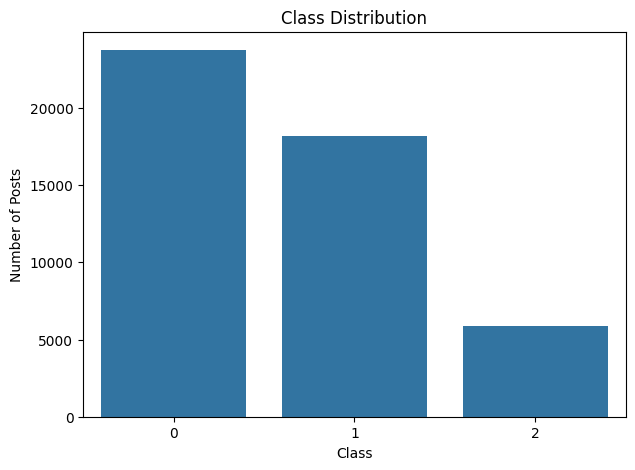

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x="y"
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Posts")
plt.show()

Basic text preprocessing

In [9]:
train_df["text"] = train_df["text"].fillna("").astype(str)
test_df["text"] = test_df["text"].fillna("").astype(str)

train_df["y"] = train_df["y"].astype(int)

print("Missing training texts:", train_df["text"].isnull().sum())
print("Missing test texts:", test_df["text"].isnull().sum())

Missing training texts: 0
Missing test texts: 0


Separate text and labels

In [10]:
X = train_df["text"]
y = train_df["y"]

print("Number of texts:", len(X))
print("Number of labels:", len(y))

Number of texts: 47817
Number of labels: 47817


Train/validation split

In [11]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 38253
Validation samples: 9564


Set random seeds

In [12]:
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


Basic text preprocessing

In [13]:
train_df["text"] = train_df["text"].fillna("").astype(str)
test_df["text"] = test_df["text"].fillna("").astype(str)

train_df["y"] = train_df["y"].astype(int)

print("Missing training texts:", train_df["text"].isnull().sum())
print("Missing test texts:", test_df["text"].isnull().sum())

Missing training texts: 0
Missing test texts: 0


Separate text and labels

In [14]:
X = train_df["text"]
y = train_df["y"]

print("Number of texts:", len(X))
print("Number of labels:", len(y))

Number of texts: 47817
Number of labels: 47817


Train/validation split

In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 38253
Validation samples: 9564


Set random seeds

In [16]:
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


## Model Preparation

The text data is tokenized using the XLM-RoBERTa tokenizer.

Each text sequence is converted into token IDs and attention masks. Sequences longer than the maximum sequence length are truncated, while shorter sequences are padded.

Load XLM-RoBERTa tokenizer

In [17]:
from transformers import AutoTokenizer

MODEL_NAME = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Tokenizer loaded successfully.


Create a PyTorch Dataset

In [18]:
class ToxicityDataset(torch.utils.data.Dataset):

    def __init__(self, texts, labels=None, tokenizer=None, max_length=128):
        self.texts = list(texts)
        self.labels = None if labels is None else list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = self.texts[index]

        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length
        )

        item = {
            "input_ids": encoding["input_ids"],
            "attention_mask": encoding["attention_mask"]
        }

        if self.labels is not None:
            item["labels"] = int(self.labels[index])

        return item

Create train and validation datasets

In [19]:
MAX_LENGTH = 256

train_dataset = ToxicityDataset(
    X_train,
    y_train,
    tokenizer,
    MAX_LENGTH
)

val_dataset = ToxicityDataset(
    X_val,
    y_val,
    tokenizer,
    MAX_LENGTH
)

print("Training dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))

Training dataset size: 38253
Validation dataset size: 9564


Load the model

In [20]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

print("Model loaded successfully.")

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.


Data collator

In [21]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

Define evaluation metrics

In [22]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro"
    )

    return {
        "accuracy": accuracy,
        "f1_macro": macro_f1
    }

## Model Training

The pre-trained XLM-RoBERTa model is fine-tuned on the competition-provided training data.

The model is trained for  epochs with a training batch size of 8. The learning rate is 2e-5 and weight decay is 0.1.

The best model is selected according to validation Macro F1-score.

Training configuration

In [34]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./xlmr_toxicity_model",

    num_train_epochs=4,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    learning_rate=2e-5,
    weight_decay=0.1,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,

    save_total_limit=2,

    logging_strategy="steps",
    logging_steps=100,

    fp16=torch.cuda.is_available(),

    report_to="none",

    seed=42
)

Create Trainer

In [25]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Trainer is ready.")

Trainer is ready.


Load XLM-RoBERTa tokenizer

In [26]:
from transformers import AutoTokenizer

MODEL_NAME = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")

Tokenizer loaded successfully.


Create a PyTorch Dataset

In [27]:
class ToxicityDataset(torch.utils.data.Dataset):

    def __init__(self, texts, labels=None, tokenizer=None, max_length=128):
        self.texts = list(texts)
        self.labels = None if labels is None else list(labels)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):

        text = self.texts[index]

        encoding = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length
        )

        item = {
            "input_ids": encoding["input_ids"],
            "attention_mask": encoding["attention_mask"]
        }

        if self.labels is not None:
            item["labels"] = int(self.labels[index])

        return item

Load the model


In [29]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3
)

print("Model loaded successfully.")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.


Data collator

In [28]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

Define evaluation metrics

In [30]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro"
    )

    return {
        "accuracy": accuracy,
        "f1_macro": macro_f1
    }

In [31]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU")

GPU available: True
GPU: Tesla T4


Create Trainer

In [32]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

print("Trainer is ready.")

Trainer is ready.


## Training

The model is now fine-tuned using the training dataset. Validation performance is monitored during training to select the best-performing model based on Macro F1-score.

Train the model

In [33]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.842216,0.866404,0.576014,0.516542
2,0.760827,0.841752,0.601840,0.551009
3,0.716327,0.868817,0.606441,0.568296
4,0.583274,0.971804,0.608427,0.565001


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=19128, training_loss=0.7567648130797383, metrics={'train_runtime': 2791.6342, 'train_samples_per_second': 54.811, 'train_steps_per_second': 6.852, 'total_flos': 3927478055730642.0, 'train_loss': 0.7567648130797383, 'epoch': 4.0})

Evaluate the best model

In [36]:
evaluation_results = trainer.evaluate()

print("\nValidation Results:")

for key, value in evaluation_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

AttributeError: `AcceleratorState` object has no attribute `distributed_type`. This happens if `AcceleratorState._reset_state()` was called and an `Accelerator` or `PartialState` was not reinitialized.

## Model Evaluation

After training, the model is evaluated on the validation dataset.

Accuracy measures the overall proportion of correct predictions, while Macro F1 gives equal importance to each of the three classes.

A classification report and confusion matrix are also generated for more detailed evaluation.

Detailed classification report

In [ ]:
validation_output = trainer.predict(val_dataset)

val_predictions = np.argmax(
    validation_output.predictions,
    axis=-1
)

print(
    classification_report(
        y_val,
        val_predictions,
        target_names=[
            "Explicitly Toxic/Hateful",
            "Subtly Toxic",
            "Non-toxic/Neutral"
        ],
        digits=4
    )
)

Confusion matrix

In [ ]:
cm = confusion_matrix(
    y_val,
    val_predictions
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Explicitly Toxic",
        "Subtly Toxic",
        "Non-toxic"
    ],
    yticklabels=[
        "Explicitly Toxic",
        "Subtly Toxic",
        "Non-toxic"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

## Test Prediction

In [ ]:
test_dataset = ToxicityDataset(
    test_df["text"],
    labels=None,
    tokenizer=tokenizer,
    max_length=MAX_LENGTH
)

print("Test dataset size:", len(test_dataset))

The best-performing model selected during validation is used to predict the labels of the unseen test dataset.

Predict the test data

In [ ]:
test_output = trainer.predict(test_dataset)

test_predictions = np.argmax(
    test_output.predictions,
    axis=-1
)

print("Number of predictions:", len(test_predictions))
print("First 20 predictions:")
print(test_predictions[:20])

## Create Submission File

The predicted labels are combined with the corresponding test IDs.

The final submission follows the required Kaggle format with two columns:

- `id`
- `y_pred`

In [ ]:
submission = pd.DataFrame({
    "id": test_df["id"],
    "y_pred": test_predictions
})

print(submission.head())
print("\nSubmission shape:", submission.shape)

Verify submission format

In [ ]:
print("Submission columns:")
print(submission.columns.tolist())

print("\nNumber of rows:")
print(len(submission))

print("\nMissing values:")
print(submission.isnull().sum())

print("\nPrediction values:")
print(sorted(submission["y_pred"].unique()))

assert list(submission.columns) == ["id", "y_pred"]
assert len(submission) == 11955
assert submission["id"].notna().all()
assert submission["y_pred"].notna().all()

print("Submission format verified successfully.")

## Save Final Submission

The verified predictions are saved as `submission.csv` in the required format.

In [ ]:
submission.to_csv(
    "submission.csv",
    index=False
)

print("submission.csv created successfully.")

Display final submission

In [ ]:
display(submission.head(10))

Download submission

In [ ]:
files.download("submission.csv")